In [1]:
import h5py, os, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# define variables 
fileDirectory = 'C:\\Users\\Admin\\UniBE\\data\\200525'
fileName = '200525_531_18_1a_DRC470_03_thre6.bxr'
wellID = 'Well_A1' # identifier of chip well to be analysed 

# open the BXR file 
file = h5py.File(os.path.join(fileDirectory,fileName), 'r')

In [3]:
# collect experiment information 
minDigitalValue = file.attrs['MinDigitalValue'] 
maxDigitalValue = file.attrs['MaxDigitalValue'] 
minAnalogValue = file.attrs['MinAnalogValue'] 
maxAnalogValue = file.attrs['MaxAnalogValue'] 
dacFactor = (maxAnalogValue - minAnalogValue) / (maxDigitalValue - minDigitalValue) 
offsetValue = minAnalogValue - dacFactor * minDigitalValue 
samplingRate = file.attrs['SamplingRate']
chIdxs = np.array(file[wellID + '/StoredChIdxs']) 

In [4]:
# collect the required spike data 
spikeDataTimestamps = file[wellID + '/SpikeTimes'][:] 
spikeDataChIdxs = file[wellID + '/SpikeChIdxs'][:]

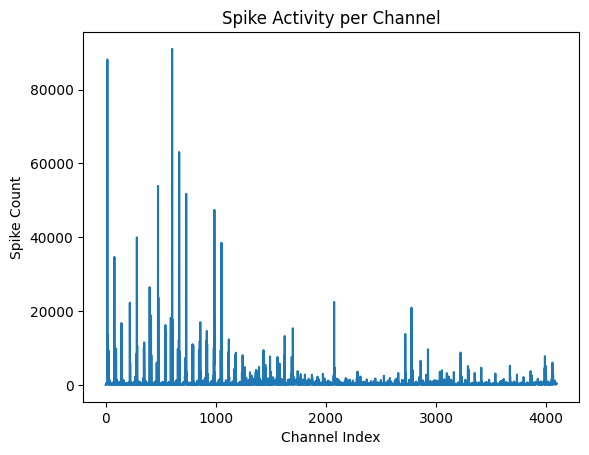

In [5]:
# Count spikes per channel
unique_channels, spike_counts = np.unique(spikeDataChIdxs, return_counts=True)
# Plot
plt.plot(unique_channels, spike_counts)
plt.xlabel('Channel Index')
plt.ylabel('Spike Count')
plt.title('Spike Activity per Channel')
plt.show()

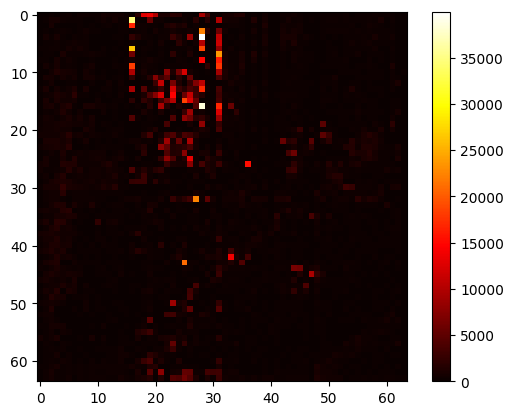

In [6]:
from collections import Counter
counts = dict(Counter(spikeDataChIdxs))

counts_array = np.zeros((64, 64))

for key in counts.keys():
    r, c = key//64, key%64
    if r == 0 and c == 1:
        counts_array[r][c] = counts[key]
    elif counts[key] > 40000:
        counts_array[r][c] = 0
    else:
        counts_array[r][c] = counts[key]

dpi = 17.5

fig = plt.Figure(figsize=(64/dpi,64/dpi), dpi=dpi)
plt.imshow(counts_array, cmap='hot', interpolation='none')
plt.axis('off')
plt.savefig(os.path.join(fileDirectory, "heatmap.png"), bbox_inches='tight', pad_inches=0, dpi=dpi)

plt.axis('on')
plt.colorbar()
plt.show()

In [7]:
import numpy.ma as ma
import seaborn as sns; sns.set_theme(style='white')
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os

# Mask and handle low values
mask = counts_array == 0
counts_masked = ma.masked_array(counts_array, mask=mask)
counts_masked[counts_masked < 1] = 1

vmin = counts_array.min()
vmax = counts_array.max()

# Set output image size to exactly 64x64 pixels
dpi = 83.5
fig = plt.figure(figsize=(1, 1), dpi=dpi)

# Plot heatmap
ax = sns.heatmap(counts_masked, cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax), cbar=False, ax=fig.add_subplot(111))
ax.axis('off')

# Save the figure
plt.savefig(os.path.join(fileDirectory, "heatmap.png"), bbox_inches='tight', pad_inches=0, dpi=dpi)
plt.close()

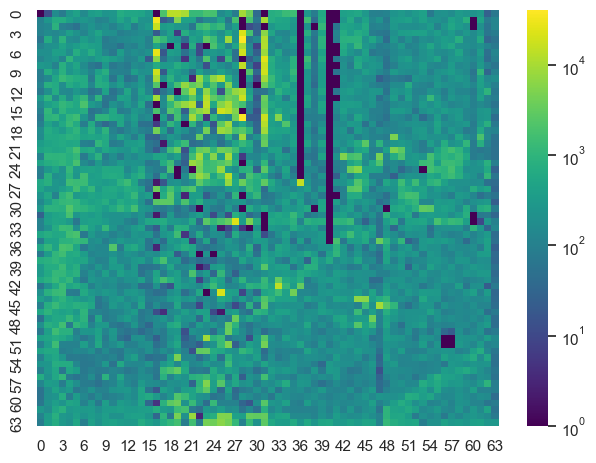

In [8]:
fig = plt.Figure(figsize=(64, 64))
ax = fig.add_subplot(1, 1, 1)

heatmap = sns.heatmap(counts_masked, cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax))

cbar = heatmap.collections[0].colorbar
cbar.ax.minorticks_off()

# Set x and y ticks every 10 positions
xticks = np.arange(0, 64, 10)
yticks = np.arange(0, 64, 10)

ax.set_xticks(xticks)
ax.set_yticks(yticks)

ax.set_xticklabels(xticks, rotation=45, ha='right')
ax.set_yticklabels(yticks)

plt.tight_layout()

In [9]:
%matplotlib Tk
img = plt.imread("C:\\Users\\Admin\\UniBE\\data\\200525\\thumbnail_IMG_3331.jpg")
plt.imshow(img)
plt.title("Click 4 Points")

points = plt.ginput(4, timeout=0)  # Click 4 points on the image

# Unzip the list of (x, y) points
x_vals, y_vals = zip(*points)
# plt.plot(x_vals, y_vals, 'bo')  # Blue circle markers

# plt.title("Selected Points")
# plt.draw()

plt.close()
print(points)
%matplotlib inline

[(np.float64(111.95238095238096), np.float64(209.0238095238094)), (np.float64(780.3333333333336), np.float64(93.78571428571422)), (np.float64(914.4285714285717), np.float64(789.4047619047618)), (np.float64(216.71428571428578), np.float64(904.6428571428571))]


In [11]:
heatmap = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\200525\\heatmap.png") 
# plt.imread --> 4-channel images (R, G, B, alpha) so use cv2.imread instead for 3-channel images

# Points on the heatmap
dst_pts = np.array([
    [0, 0],      # top-left of heatmap
    [63, 0],     # top-right
    [63, 63],    # bottom-rigt
    [0, 63]      # bottom-left
], dtype=np.float32)

# Corresponding points on the image
src_pts = np.array(points, dtype=np.float32)

# Transform
matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)

# wrap heatmap to image shape
height, width, _ = heatmap.shape
wrapped_img = cv2.warpPerspective(img, matrix, (width, height))

# Normalise and colour heatmap
img_norm = cv2.normalize(wrapped_img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
img_colour = cv2.applyColorMap(img_norm, cv2.COLORMAP_JET)

# Overlay
alpha = 0.5
overlay = cv2.addWeighted(heatmap, 1-alpha, cv2.cvtColor(img_colour, cv2.COLOR_RGB2BGR), alpha, 0)

# Display
cv2.imshow("Overlay", overlay)
cv2.imwrite('overlay.png', overlay)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [15]:
height, width = overlay.shape[:2]

dst = cv2.resize(overlay, (10*width, 10*height), interpolation = cv2.INTER_CUBIC)

cv2.imshow("Overlay", dst)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [9]:
# Region selection

# Variables for drawing and storing coordinates
drawing = False  # True if mouse is pressed
mode = True      # True for drawing curves/lines
contour = []     # Stores the drawn shape coordinates

# Mouse callback function
def draw(event, x, y, flags, param):
    global current_x, current_y, drawing, mode, contour

    if event == cv2.EVENT_LBUTTONDOWN:
        drawing = True
        current_x, current_y = x, y
        contour.append((x, y))  # start point

    elif event == cv2.EVENT_MOUSEMOVE:
        if drawing:
            if mode:
                cv2.line(im, (current_x, current_y), (x, y), (0, 0, 255), 2)
                current_x, current_y = x, y
                contour.append((x, y))

    elif event == cv2.EVENT_LBUTTONUP:
        drawing = False
        if mode:
            cv2.line(im, (current_x, current_y), (x, y), (0, 0, 255), 2)
            contour.append((x, y))
            
            # Close the shape by connecting to the start
            if len(contour) > 2:
                cv2.line(im, (x, y), contour[0], (0, 0, 255), 2)

# Load image
im = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\130225\\thumbnail_IMG_1950_2.jpg")

# Create window and set mouse callback
cv2.namedWindow("Bill BEGUERADJ OpenCV")
cv2.setMouseCallback('Bill BEGUERADJ OpenCV', draw)

# Display loop
while True:
    cv2.imshow('Bill BEGUERADJ OpenCV', im)
    k = cv2.waitKey(1) & 0xFF
    if k == ord('m'):
        mode = not mode
    elif k == 27:  # ESC to quit
        break

cv2.destroyAllWindows()

# Transform
contour = np.array(contour, dtype=np.float32).reshape(-1, 1, 2)
print(contour.shape)
transformed_contour = cv2.perspectiveTransform(contour, matrix)

(5, 1, 2)


In [9]:
# Contour detection
img_copy = img.copy()
gray = cv2.cvtColor(img_copy, cv2.COLOR_BGR2GRAY)

_, thresholded = cv2.threshold(gray, 35, 255, cv2.THRESH_BINARY_INV)

cv2.imshow("Thresholded", thresholded)
cv2.waitKey(0)  # Wait for any key press to close the window
cv2.destroyAllWindows()
    
# rectangular kernel (5x5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))    # General kernel size
cleaned = cv2.morphologyEx(thresholded, cv2.MORPH_OPEN, kernel)  # Remove noise
closed = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)      # Fill gaps

# Find contours
inverted = cv2.bitwise_not(thresholded)
contours, _ = cv2.findContours(inverted, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

for contour in contours:
    area = cv2.contourArea(contour)
    if area > 10000:
        print(area)
        best_contour = contour

# Transform
contour = best_contour.astype('float32') # Ensure type is float32
transformed_contour = cv2.perspectiveTransform(contour, matrix)


236550.5


In [10]:
print(transformed_contour.shape)
new_points = []
contour_copy = np.copy(transformed_contour)

for i in range(len(transformed_contour)-1):
    x, y = transformed_contour[i][0]
    next_point = transformed_contour[i+1][0]
    for dx, dy in [(-1,0), (0,1), (1,0), (0,-1)]:
        neighbour = np.array([x + dx, y + dy])
        if not np.array_equal(next_point, neighbour):
            new_points.append([[neighbour[0], neighbour[1]]])  # keep consistent shape

# Convert to correct shape and append
if new_points:
    # new_points_array = np.array(new_points, dtype=copy.dtype)
    contour_copy = np.vstack([contour_copy, new_points])

# copy = np.sort(copy, axis=0)
contour_copy = np.array(sorted(contour_copy, key=lambda x: x[0][0]), dtype=object)
print(contour_copy.shape)

cv2.drawContours(overlay, [contour_copy.astype(int)], 0, (255, 0, 0), 2)
cv2.imshow("Contours", overlay)
cv2.imwrite('countours.png', overlay)
cv2.waitKey(0)
cv2.destroyAllWindows()

(2115, 1, 2)
(10571, 1, 2)


In [11]:
cv2.drawContours(overlay, [transformed_contour.astype(int)], 0, (0, 255, 0), 2)
cv2.imshow("Contours", overlay)
cv2.imwrite('countours.png', overlay)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [12]:
cv2.drawContours(heatmap, [contour_copy.astype(int)], 0, (0, 255, 0), thickness=cv2.FILLED)
cv2.imwrite('image1.png', heatmap)
cv2.destroyAllWindows()

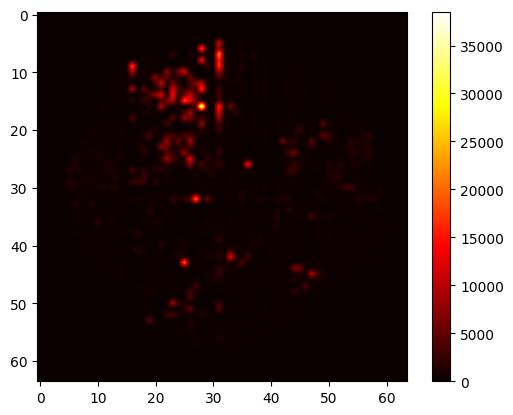

In [13]:
%matplotlib inline
mask = np.all(heatmap == [0, 255, 0], axis=-1)  # take extra channels
coords = np.column_stack(np.where(mask))
cleaned_heatmap = np.zeros((64, 64))
channels = []
for point in coords:
    x, y = point
    cleaned_heatmap[x][y] = counts_array[x][y]
    channels.append(64*x+y)
    # coordinate conventions differ between image and heatmaps (i.e., x and y are flipped)

cleaned_heatmap[0][1] = counts_array[0][1]
channels.append(64*0+1)

fig = plt.Figure()
plt.imshow(cleaned_heatmap, cmap='hot', interpolation='bilinear')
plt.axis('on')
plt.colorbar()
plt.show()

In [14]:
mask = np.isin(spikeDataChIdxs, channels)
spikeDataChIdxs[np.where(~mask)] = 0

Spike sorting

In [15]:
# Strta and end of recording interval
dataStartPositionSec = 0
dataDurationSec = 797.07

# convert the requested time interval from seconds to frames 
startFrame = int(dataStartPositionSec * samplingRate) 
nFrames = int(dataDurationSec * samplingRate) 
print('frames', startFrame, nFrames)

# collect the TOCs 
toc = np.array(file['TOC']) 
spikeToc = np.array(file[wellID + '/SpikeTOC']) 
 
# from the given start position and duration (in frames), find the corresponding range of spike positions using the TOC 
tocStartIdx = np.searchsorted(toc[:, 1], startFrame) 
tocEndIdx = min(np.searchsorted(toc[:, 1], startFrame + nFrames, side='right') + 1, len(toc) - 1) 
spikeStart = spikeToc[tocStartIdx]
spikeEnd = spikeToc[tocEndIdx]

frames 0 8052858


In [16]:
waveformLength = file[wellID + '/SpikeForms'].attrs['Wavelength'] 
print(waveformLength)
spikeDataWaveforms = file[wellID + '/SpikeForms'][spikeStart*waveformLength:spikeEnd*waveformLength] 

31


In [22]:
waveformData = [] 
chIdx = 64*0+1
for idx, ch in enumerate(spikeDataChIdxs): 
    if ch == chIdx and startFrame <= spikeDataTimestamps[idx] < startFrame + nFrames:
        waveformData.append(spikeDataWaveforms[idx*waveformLength:idx*waveformLength+waveformLength])

In [23]:
len(waveformData)

12

In [25]:
%matplotlib Tk
x = (np.arange(0, waveformLength, 1) / samplingRate)*1000 
fig, ax = plt.subplots()
for i in range(len(waveformData)):
    # convert the waveform to analog 
    y = offsetValue + dacFactor * waveformData[i]
    ax.plot(x, y)

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pcs = pca.fit_transform(waveformData)

In [ ]:
%matplotlib tk
from matplotlib.widgets import RectangleSelector

def on_select(eclick, erelease):
    x_min = min(eclick.xdata, erelease.xdata)
    x_max = max(eclick.xdata, erelease.xdata)
    y_min = min(eclick.ydata, erelease.ydata)
    y_max = max(eclick.ydata, erelease.ydata)

    mask = (pcs[:, 0] >= x_min) & (pcs[:, 0] <= x_max) & \
                (pcs[:, 1] >= y_min) & (pcs[:, 1] <= y_max)

    print(mask)

    print(waveformData[mask])

fig, ax = plt.subplots()
ax.scatter(pcs[:, 0], pcs[:, 1], s=1)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title(f'PCA of Spike Waveforms - Channel {chIdx}')

selector = RectangleSelector(
    ax, on_select,
    useblit=True,          # safer and more compatible
    button=[1, 3],             # left click only
    minspanx=0, minspany=0,
    spancoords='pixels',
    interactive=True
)

plt.show()

[ True False False  True  True False False  True False False  True  True
  True  True  True False  True  True  True  True  True False  True  True
 False False  True False  True  True False False False False  True False
  True False False  True False False False False  True  True False  True
  True  True  True  True False  True False  True  True False False False
 False  True False  True  True False False  True False  True False  True
 False  True False False False False False  True False  True False  True
  True  True  True  True False False  True  True False False  True False
  True False  True  True  True  True  True  True False  True  True False
 False  True False  True False False False False  True  True  True  True
 False  True False  True  True False False False False  True  True  True
 False False  True  True False  True  True  True  True False  True  True
 False  True  True  True False  True  True False False  True  True False
 False  True False False False False False  True  T

Traceback (most recent call last):
  File "c:\Users\Admin\UniBE\spike-sort\venv\Lib\site-packages\matplotlib\cbook.py", line 361, in process
    func(*args, **kwargs)
    ~~~~^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\UniBE\spike-sort\venv\Lib\site-packages\matplotlib\widgets.py", line 2276, in release
    self._release(event)
    ~~~~~~~~~~~~~^^^^^^^
  File "c:\Users\Admin\UniBE\spike-sort\venv\Lib\site-packages\matplotlib\widgets.py", line 3297, in _release
    self.onselect(self._eventpress, self._eventrelease)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\AppData\Local\Temp\ipykernel_32736\1333744937.py", line 15, in on_select
    print(waveformData[mask])
          ~~~~~~~~~~~~^^^^^^
TypeError: only integer scalar arrays can be converted to a scalar index
